# Tái hiện Thực nghiệm Bài báo Fast-BNS (IPDPS 2022) — Fig. 3 & Fig. 4

Notebook này tự động chạy thực nghiệm học cấu trúc mạng Bayes (**PC-Stable / Fast-BNS**) trên 4 mạng chuẩn (`Alarm`, `Insurance`, `Hepar2`, `Munin1`) và vẽ lại **Fig. 3** & **Fig. 4** của bài báo [SOURCE_PAPER.md](../docs/papers/SOURCE_PAPER.md).

* **Môi trường chạy:** `conda activate islp`
* **Thư mục lưu hình ảnh & số liệu:** `notebooks/figures/`

In [2]:
import os
import re
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else "/home/uyenuyen/c_project/FastPGM"
FASTPGM_BIN  = os.path.join(PROJECT_ROOT, "build", "fastpgm")
DATASET_DIR  = os.path.join(PROJECT_ROOT, "dataset")
FIGURES_DIR  = os.path.join(PROJECT_ROOT, "notebooks", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

NETWORKS = ["alarm", "insurance", "hepar2", "munin1"]
TITLES   = {
    "alarm": "(a) Alarm",
    "insurance": "(b) Insurance",
    "hepar2": "(c) Hepar2",
    "munin1": "(d) Munin1"
}

print("PROJECT_ROOT:", PROJECT_ROOT)
print("FASTPGM_BIN :", FASTPGM_BIN)
print("FIGURES_DIR :", FIGURES_DIR)

PROJECT_ROOT: /home/uyenuyen/c_project/FastPGM
FASTPGM_BIN : /home/uyenuyen/c_project/FastPGM/build/fastpgm
FIGURES_DIR : /home/uyenuyen/c_project/FastPGM/notebooks/figures


## 1. Kiểm tra & Sinh dữ liệu mẫu (`s5000`, `s10000`, `s15000`) từ file `.bif`
Nếu bất kỳ tập mẫu nào trong 4 mạng (`alarm`, `insurance`, `hepar2`, `munin1`) chưa tồn tại, hàm dưới đây sẽ đọc trực tiếp file `.bif` và sinh mẫu theo thứ tự tô-pô.

In [3]:
def parse_bif_and_sample_csv(bif_path, out_path, n_samples, seed=42):
    with open(bif_path, "r") as f:
        text = f.read()
    var_order, states = [], {}
    for m in re.finditer(r"variable\s+(\S+)\s*\{\s*type\s+discrete\s*\[\s*\d+\s*\]\s*\{\s*([^}]+)\}", text):
        var = m.group(1)
        vals = [v.strip().rstrip(",") for v in m.group(2).replace(",", " ").split() if v.strip()]
        var_order.append(var)
        states[var] = vals

    parents, cpts = {}, {}
    for m in re.finditer(r"probability\s*\(\s*([^)]+)\)\s*\{([^}]+)\}", text):
        header, body = m.group(1).strip(), m.group(2).strip()
        if "|" in header:
            child, par_str = header.split("|")
            child = child.strip()
            pars = [p.strip().rstrip(",") for p in par_str.replace(",", " ").split() if p.strip()]
        else:
            child, pars = header.strip(), []
        parents[child] = pars
        if not pars:
            tm = re.search(r"table\s+([^;]+);", body)
            probs = [float(x) for x in tm.group(1).replace(",", " ").split()]
            cpts[child] = probs
        else:
            table = {}
            for line in body.splitlines():
                line = line.strip()
                if line.startswith("("):
                    tup_str, prob_str = line.split(")")
                    key = tuple(v.strip() for v in tup_str[1:].split(","))
                    probs = [float(x) for x in prob_str.rstrip(";").replace(",", " ").split()]
                    table[key] = probs
            cpts[child] = table

    topo, visited = [], set()
    while len(topo) < len(var_order):
        for v in var_order:
            if v not in visited and all(p in visited for p in parents[v]):
                topo.append(v)
                visited.add(v)

    rng = random.Random(seed)
    with open(out_path, "w") as out:
        out.write(",".join(var_order) + "\n")
        for _ in range(n_samples):
            row = {}
            for v in topo:
                vals = states[v]
                probs = cpts[v] if not parents[v] else cpts[v][tuple(row[p] for p in parents[v])]
                row[v] = rng.choices(vals, weights=probs, k=1)[0]
            out.write(",".join(row[v] for v in var_order) + "\n")
    print("Đã sinh:", out_path)

for net in NETWORKS:
    bif = os.path.join(DATASET_DIR, net, f"{net}.bif")
    for n in [5000, 10000, 15000]:
        out = os.path.join(DATASET_DIR, net, f"{net}_s{n}")
        if not os.path.exists(out):
            parse_bif_and_sample_csv(bif, out, n, seed=n)
        else:
            print(f"[OK] Đã có sẵn: {out}")

[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/alarm/alarm_s5000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/alarm/alarm_s10000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/alarm/alarm_s15000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/insurance/insurance_s5000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/insurance/insurance_s10000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/insurance/insurance_s15000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/hepar2/hepar2_s5000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/hepar2/hepar2_s10000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/hepar2/hepar2_s15000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/munin1/munin1_s5000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/munin1/munin1_s10000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/munin1/munin1_s15000


## 2. Hàm gọi `./fastpgm` và trích xuất thời gian thực thi + số phép kiểm định CI

In [4]:
def run_fastpgm(net, sample_size, threads, group_size=1):
    """Chạy ./fastpgm và trả về (thời gian pc-stable (giây), tổng số CI tests)."""
    cmd = [
        FASTPGM_BIN,
        "-j", "0", "-m", "0",
        "-t", str(threads),
        "-g", str(group_size),
        "-a", "0.05",
        "-ss", "0",
        "-f2", f"{net}/{net}_s{sample_size}"
    ]
    res = subprocess.run(cmd, capture_output=True, text=True, check=True)
    time_m = re.search(r"pc-stable:\s*([0-9.eE+-]+)\s*s", res.stdout)
    ci_m   = re.search(r"# of CI-tests =\s*(\d+)", res.stdout)
    return float(time_m.group(1)), int(ci_m.group(1))

## 3. Thực nghiệm & Vẽ **Fig. 3**: Speedup theo Số luồng và Kích thước mẫu (`5000`, `10000`, `15000`)

In [5]:
THREADS_LIST = [1, 2, 4, 8, 12]
SAMPLE_SIZES = [5000, 10000, 15000]
fig3_csv = os.path.join(FIGURES_DIR, "fig3_results.csv")

if os.path.exists(fig3_csv):
    print(f"Đọc kết quả đã lưu từ {fig3_csv} (xóa file này nếu muốn chạy lại từ đầu)...")
    df_fig3 = pd.read_csv(fig3_csv)
else:
    fig3_records = []
    for net in NETWORKS:
        for s in SAMPLE_SIZES:
            t1_time = None
            for t in THREADS_LIST:
                exec_time, ci_tests = run_fastpgm(net, s, threads=t, group_size=1)
                if t == 1:
                    t1_time = exec_time
                speedup = t1_time / exec_time
                fig3_records.append({
                    "net": net, "samples": s, "threads": t,
                    "time": exec_time, "speedup": speedup, "ci_tests": ci_tests
                })
                print(f"[Fig.3] {net:9s} | s={s:5d} | t={t:2d} -> time={exec_time:.4f}s | speedup={speedup:.2f}x")
    df_fig3 = pd.DataFrame(fig3_records)
    df_fig3.to_csv(fig3_csv, index=False)

display(df_fig3.head(15))

Đọc kết quả đã lưu từ /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig3_results.csv (xóa file này nếu muốn chạy lại từ đầu)...


,net,samples,threads,time,speedup,ci_tests
0,alarm,5000,1,0.138201,1.000000,5206
1,alarm,5000,2,0.124221,1.112541,5206
2,alarm,5000,4,0.338915,0.407775,5206
3,alarm,5000,8,0.299386,0.461615,5206
4,alarm,10000,1,0.274706,1.000000,6265
5,alarm,10000,2,0.166094,1.653919,6265
6,alarm,10000,4,0.150392,1.826600,6265
7,alarm,10000,8,0.113108,2.428705,6265
8,alarm,15000,1,0.486626,1.000000,5873
9,alarm,15000,2,0.367378,1.324592,5873


Đã lưu hình Fig. 3 tại: /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig3_speedup_sample_size.png


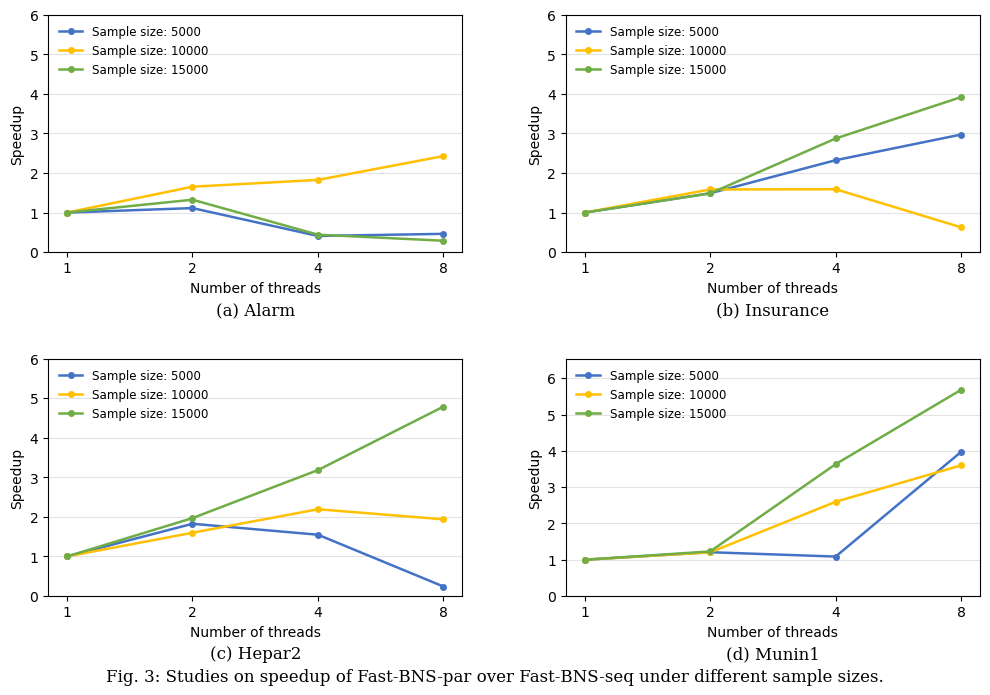

In [6]:
# Vẽ biểu đồ Fig. 3 và lưu vào notebooks/figures/
fig, axes = plt.subplots(2, 2, figsize=(10, 7.2))
colors = {5000: "#4472C4", 10000: "#FFC000", 15000: "#70AD47"}

for ax, net in zip(axes.flat, NETWORKS):
    sub = df_fig3[df_fig3["net"] == net]
    for s in SAMPLE_SIZES:
        s_df = sub[sub["samples"] == s]
        ax.plot(
            [str(t) for t in s_df["threads"]],
            s_df["speedup"],
            marker="o", markersize=4, linewidth=1.8,
            color=colors[s], label=f"Sample size: {s}"
        )
    ax.set_xlabel("Number of threads", fontsize=10)
    ax.set_ylabel("Speedup", fontsize=10)
    ax.set_ylim(0, max(sub["speedup"].max() * 1.15, 6))
    ax.set_title(TITLES[net], y=-0.30, fontsize=12, fontfamily="serif")
    ax.grid(axis="y", linestyle="-", alpha=0.35)
    ax.legend(fontsize=8.5, frameon=False, loc="upper left")

plt.suptitle("Fig. 3: Studies on speedup of Fast-BNS-par over Fast-BNS-seq under different sample sizes.", y=0.02, fontsize=12, fontfamily="serif")
plt.tight_layout()
plt.subplots_adjust(bottom=0.12, hspace=0.45, wspace=0.25)

fig3_png = os.path.join(FIGURES_DIR, "fig3_speedup_sample_size.png")
fig3_pdf = os.path.join(FIGURES_DIR, "fig3_speedup_sample_size.pdf")
plt.savefig(fig3_png, dpi=300, bbox_inches="tight")
plt.savefig(fig3_pdf, bbox_inches="tight")
print("Đã lưu hình Fig. 3 tại:", fig3_png)
plt.show()

## 4. Thực nghiệm & Vẽ **Fig. 4**: Ảnh hưởng của `Group size` (`gs`) đến Thời gian thực thi & Số lượng CI tests

In [7]:
GROUP_SIZES = [1, 2, 4, 6, 8, 10, 12, 14, 16]
NUM_THREADS_FIG4 = 12
fig4_csv = os.path.join(FIGURES_DIR, "fig4_results.csv")

if os.path.exists(fig4_csv):
    print(f"Đọc kết quả đã lưu từ {fig4_csv} (xóa file này nếu muốn chạy lại từ đầu)...")
    df_fig4 = pd.read_csv(fig4_csv)
else:
    fig4_records = []
    for net in NETWORKS:
        base_ci = None
        for gs in GROUP_SIZES:
            exec_time, ci_tests = run_fastpgm(net, sample_size=10000, threads=NUM_THREADS_FIG4, group_size=gs)
            if gs == 1:
                base_ci = ci_tests
            inc_pct = (ci_tests - base_ci) / base_ci * 100.0
            fig4_records.append({
                "net": net, "gs": gs, "time": exec_time,
                "ci_tests": ci_tests, "inc_pct": inc_pct
            })
            print(f"[Fig.4] {net:9s} | gs={gs:2d} -> time={exec_time:.4f}s | CI={ci_tests} (+{inc_pct:.2f}%)")
    df_fig4 = pd.DataFrame(fig4_records)
    df_fig4.to_csv(fig4_csv, index=False)

display(df_fig4.head(18))

[Fig.4] alarm     | gs= 1 -> time=0.5630s | CI=6265 (+0.00%)
[Fig.4] alarm     | gs= 2 -> time=0.5670s | CI=6399 (+2.14%)
[Fig.4] alarm     | gs= 4 -> time=0.5251s | CI=6657 (+6.26%)
[Fig.4] alarm     | gs= 6 -> time=0.4227s | CI=6905 (+10.22%)
[Fig.4] alarm     | gs= 8 -> time=0.3024s | CI=7188 (+14.73%)
[Fig.4] alarm     | gs=10 -> time=0.3171s | CI=7310 (+16.68%)
[Fig.4] alarm     | gs=12 -> time=0.3039s | CI=7489 (+19.54%)
[Fig.4] alarm     | gs=14 -> time=0.2948s | CI=7620 (+21.63%)
[Fig.4] alarm     | gs=16 -> time=0.2657s | CI=7736 (+23.48%)
[Fig.4] insurance | gs= 1 -> time=2.6012s | CI=9825 (+0.00%)
[Fig.4] insurance | gs= 2 -> time=1.5236s | CI=9942 (+1.19%)
[Fig.4] insurance | gs= 4 -> time=1.1518s | CI=10186 (+3.67%)
[Fig.4] insurance | gs= 6 -> time=0.8936s | CI=10450 (+6.36%)
[Fig.4] insurance | gs= 8 -> time=0.6312s | CI=10762 (+9.54%)
[Fig.4] insurance | gs=10 -> time=0.8037s | CI=11072 (+12.69%)
[Fig.4] insurance | gs=12 -> time=0.5091s | CI=11477 (+16.81%)
[Fig.4] ins

,net,gs,time,ci_tests,inc_pct
0,alarm,1,0.562995,6265,0.000000
1,alarm,2,0.567020,6399,2.138867
2,alarm,4,0.525059,6657,6.256983
3,alarm,6,0.422658,6905,10.215483
4,alarm,8,0.302387,7188,14.732642
5,alarm,10,0.317072,7310,16.679968
6,alarm,12,0.303906,7489,19.537111
7,alarm,14,0.294818,7620,21.628093
8,alarm,16,0.265665,7736,23.479649
9,insurance,1,2.601150,9825,0.000000


Đã lưu hình Fig. 4 tại: /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig4_group_size_effect.png


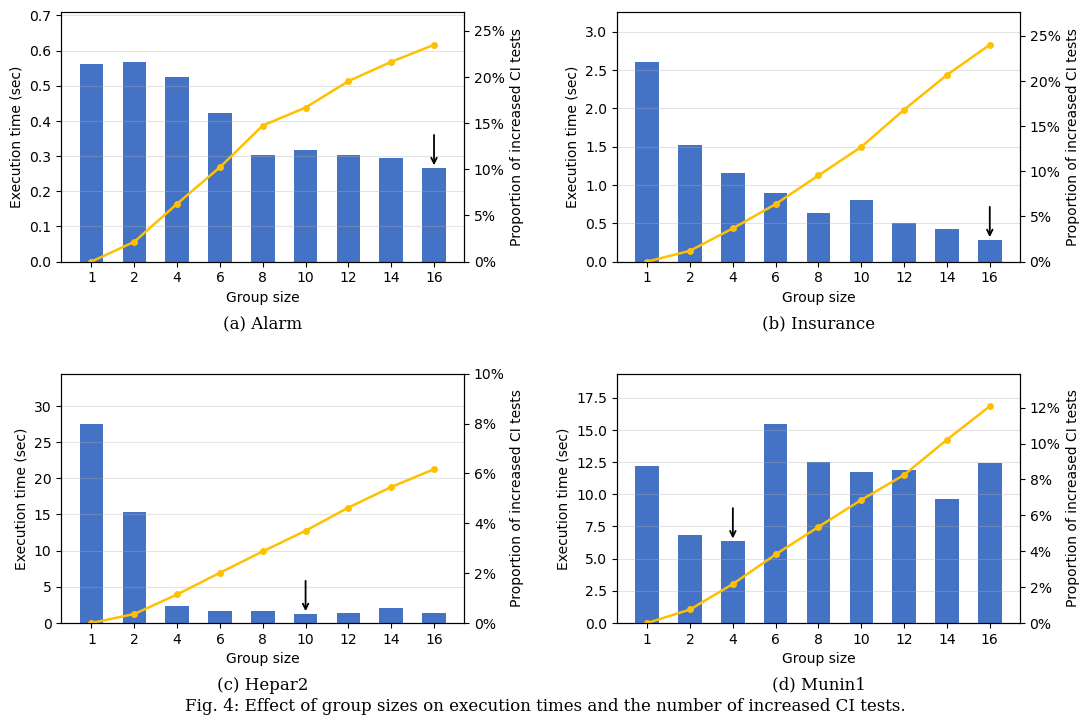

In [8]:
# Vẽ biểu đồ Fig. 4 và lưu vào notebooks/figures/
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

for ax1, net in zip(axes.flat, NETWORKS):
    sub = df_fig4[df_fig4["net"] == net].reset_index(drop=True)
    x = np.arange(len(sub))

    # Trục trái (Cột xanh): Execution time (sec)
    ax1.bar(x, sub["time"], width=0.55, color="#4472C4")
    ax1.set_xticks(x)
    ax1.set_xticklabels(sub["gs"])
    ax1.set_xlabel("Group size", fontsize=10)
    ax1.set_ylabel("Execution time (sec)", fontsize=10)
    ax1.set_ylim(0, sub["time"].max() * 1.25)
    ax1.grid(axis="y", linestyle="-", alpha=0.35)

    # Vẽ mũi tên đen chỉ vào Group size có thời gian chạy ngắn nhất
    best_idx = sub["time"].idxmin()
    best_y   = sub.loc[best_idx, "time"]
    ax1.annotate(
        "",
        xy=(best_idx, best_y),
        xytext=(best_idx, best_y + sub["time"].max() * 0.18),
        arrowprops=dict(arrowstyle="->", color="black", lw=1.3)
    )

    # Trục phải (Đường vàng): Proportion of increased CI tests (%)
    ax2 = ax1.twinx()
    ax2.plot(x, sub["inc_pct"], color="#FFC000", marker="o", markersize=4, linewidth=1.8)
    ax2.set_ylabel("Proportion of increased CI tests", fontsize=10)
    ax2.set_ylim(0, max(sub["inc_pct"].max() * 1.15, 10))
    ax2.yaxis.set_major_formatter(lambda val, pos: f"{int(round(val))}%")

    ax1.set_title(TITLES[net], y=-0.30, fontsize=12, fontfamily="serif")

plt.suptitle("Fig. 4: Effect of group sizes on execution times and the number of increased CI tests.", y=0.02, fontsize=12, fontfamily="serif")
plt.tight_layout()
plt.subplots_adjust(bottom=0.12, hspace=0.45, wspace=0.38)

fig4_png = os.path.join(FIGURES_DIR, "fig4_group_size_effect.png")
fig4_pdf = os.path.join(FIGURES_DIR, "fig4_group_size_effect.pdf")
plt.savefig(fig4_png, dpi=300, bbox_inches="tight")
plt.savefig(fig4_pdf, bbox_inches="tight")
print("Đã lưu hình Fig. 4 tại:", fig4_png)
plt.show()